1. **lagrangian analysis:** three subplots containing the 50-m advection, in (a) back track, (b) east releasing and (c) north releasing. The figure must contain:
	1. isobaths (200, 1000, 2000, 4000)
	2. coordinates in the left and bottom axis
	3. the releasing point in red
	4. name of main places (Guanabara, Cabo Frio, Cabo São Tomé, Tubarão Bight)

In [1]:
import xarray as xr
import numpy as np
import math
from datetime import timedelta,datetime
from operator import attrgetter
import matplotlib.pyplot as plt
import cartopy.feature as cfeature
import cartopy.crs as ccrs

import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

import sys
sys.path.insert(0, '/home/danilo/phd/thesis/chapter_colab/scripts/')
from load_profiles import load_vertical_profiles
from utils import subplots_structure

In [2]:
dict_casts = load_vertical_profiles()

# plotting with my functions
zoomed_extent= [-50, -37, -30, -22] #[-45, -39, -27, -22]

Processing cast1...
Processing cast2...
Processing cast3.2...
Processing cast6...
Processing cast7...


In [3]:
# glorys_current_fields = xr.open_dataset('/home/danilo/phd/thesis/chapter_colab/data/sanagu2022/glorys_current_*.nc')

experiments = {
    "smax_from_backpropag_cmems": {
                'outfile': xr.open_zarr('/home/danilo/phd/thesis/chapter_colab/scripts/lagrangean/smax_from_backpropag_cmems.zarr'),
                'center_launch': [-42.768, -23.64],
                },
    "smax_from_backpropag_isopycnal": {
                'outfile': xr.open_zarr('/home/danilo/phd/thesis/chapter_colab/scripts/lagrangean/smax_from_backpropag_cmems_isopycnal.zarr/'),
                'center_launch': [-42.768, -23.64],
                },
    # "smax_from_east_cmems": {
    #             'outfile': xr.open_zarr('/home/danilo/phd/thesis/chapter_colab/scripts/lagrangean/smax_from_east_cmems.zarr'),
    #             'center_launch': [-39, -26.5],
    #             },
    # "smax_from_north_cmems": {
    #             'outfile': xr.open_zarr('/home/danilo/phd/thesis/chapter_colab/scripts/lagrangean/smax_from_north_cmems.zarr'),
    #             'center_launch': [-40, -22],
    #             },
}
experiments.keys()

dict_keys(['smax_from_backpropag_cmems', 'smax_from_backpropag_isopycnal'])

In [9]:
zoomed_extent = [-50, -37, -30, -21.5]
zoomed_extent = [-45, -37, -27, -19]

bathy = xr.open_dataset('../data/gebco_updated.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

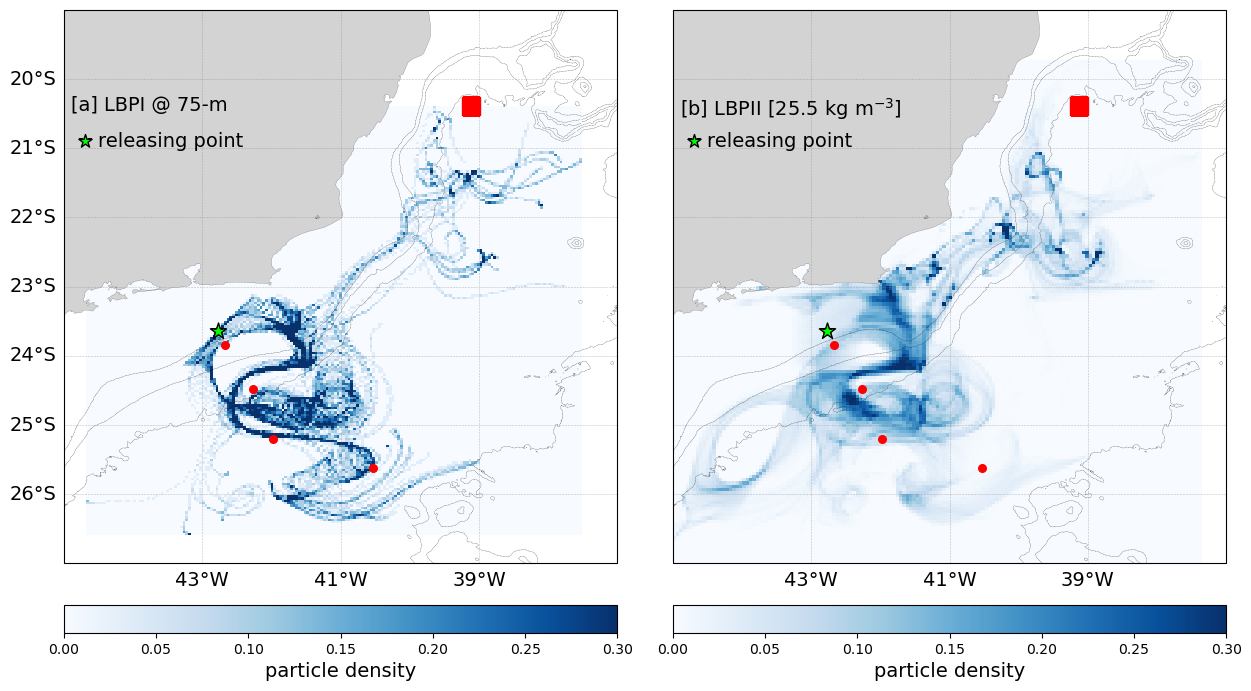

In [10]:
fig,axes = subplots_structure(2, 1, (15,18), 2)
# titles = ['[a] back propagation @ 50-m', '[b] Isopycnal surface advection [25.5]', '[b] east release @ 75-m' ,'[c] north release @ 75-m']
titles = ['[a] LBPI @ 75-m', r'[b] LBPII [25.5 kg m$^{-3}$]']
# titles = ['[a] LBPI', '[b] LBPII', '[c] LFPE', '[d] LFPN']
maxvalues = [0.3, 0.3]

cont = 0

for key,ax in zip(experiments.keys(), axes):
    p = experiments[key]['outfile']
    lons = p.lon.values[~np.isnan(p.lon.values)].ravel()
    lats = p.lat.values[~np.isnan(p.lat.values)].ravel()
    _ = ax.hist2d(lons, lats, bins=180, cmap='Blues', density=True, vmin=0, vmax=maxvalues[cont])
    cb = plt.colorbar(_[-1], location='bottom', pad=.03)
    cb.set_label('particle density', fontsize=14)
    
    ax.set_extent(zoomed_extent, crs=ccrs.PlateCarree())

    states_provinces = cfeature.NaturalEarthFeature(
            category='physical',name='coastline',scale='10m',
            facecolor='lightgray')
    ax.add_feature(states_provinces, edgecolor='black',linewidth=.1)

    ### CONFIGURING MERIDIANS AND PARALLELS
    gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=.4,
                    color='gray', alpha=0.5, linestyle='--',
                    xlocs=list(np.arange(zoomed_extent[0], zoomed_extent[1], 2)),
                    ylocs=list(np.arange(zoomed_extent[2], zoomed_extent[3], 1)),)

    if cont in [0,2]:
        gl.xlabels_top = False
        gl.ylabels_right = False
    else:
        gl.xlabels_top = False
        gl.ylabels_right = False
        gl.ylabels_left = False

    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.ylabel_style = {'color': 'black', 'fontsize': '14'}
    gl.xlabel_style = {'color': 'black', 'fontsize': '14'}
    
    # plotting selected profiles locations
    for cast,values in dict_casts.items():
        prof = values['prof']
        str_time = values['time'].strftime("%m/%d")
        xlon = values['xlon']
        ylat = values['ylat']

        ax.scatter(xlon, ylat, c='r', s=30)

    ax.scatter(experiments[key]['center_launch'][0], experiments[key]['center_launch'][1],
               marker='*', c='lime', s=150, zorder=10, edgecolor='k')
    ax.scatter( -39.122001059015886,-20.390281295192196, marker='s', c='r', zorder=10, s=150)
    
    # ax.set_title(titles[cont], loc='left', fontsize=14, y=0.90)
    ax.text(-44.9, -20.25, titles[cont], fontsize=14, ha='left', va='top')
    ax.scatter(-44.7, -20.9, marker='*', c='lime', s=100, zorder=10, edgecolor='k')
    ax.text(-44.5, -20.9, 'releasing point', fontsize=14, ha='left', va='center')
    bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -2000, -4000], 
                             colors=('k'), linewidths=(0.2), linestyles=('--'))
    
    cont += 1

plt.subplots_adjust(hspace=-0.45, wspace=.1)

fig.patch.set_alpha(1.0)
# plt.savefig('../figures/manuscript/00_manuscript_lagrangian_analysis_backpropagation.png', bbox_inches="tight", dpi=300)

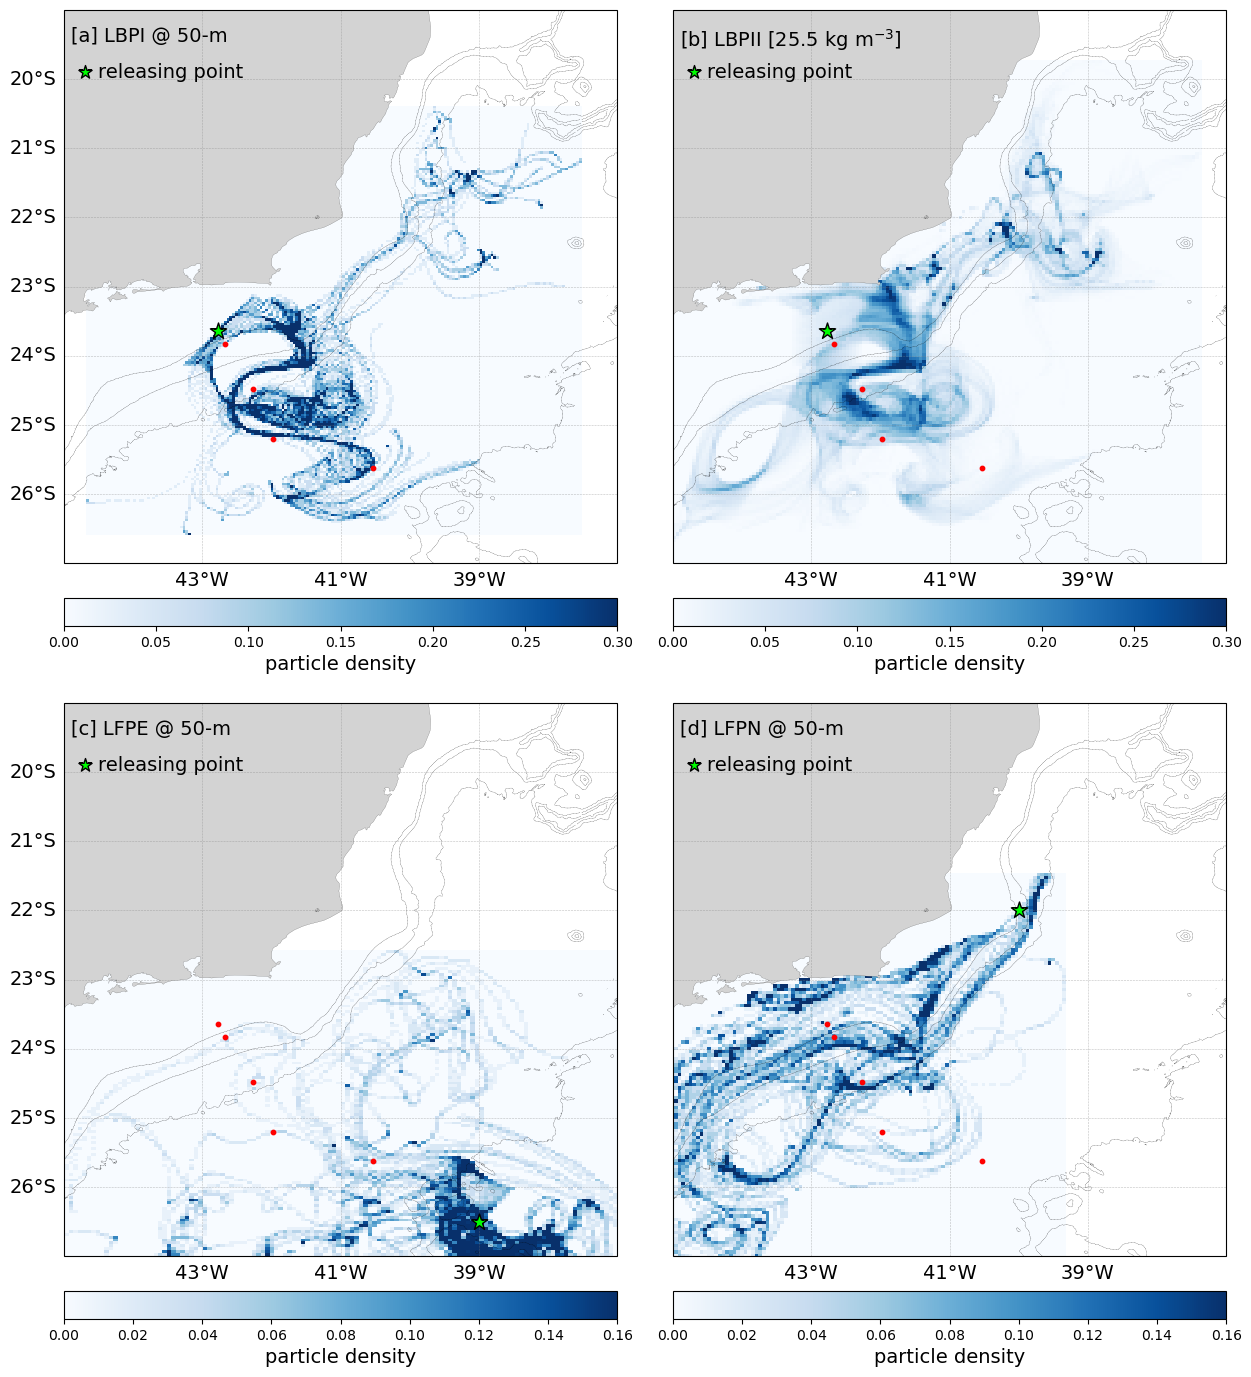

In [15]:
# glorys_current_fields = xr.open_dataset('/home/danilo/phd/thesis/chapter_colab/data/sanagu2022/glorys_current_*.nc')

experiments = {
    "smax_from_backpropag_cmems": {
                'outfile': xr.open_zarr('../data/lagrangean/smax_from_backpropag_cmems.zarr'),
                'center_launch': [-42.768, -23.64],
                },
    "smax_from_backpropag_isopycnal": {
                'outfile': xr.open_zarr('../data/lagrangean/smax_from_backpropag_cmems_isopycnal.zarr/'),
                'center_launch': [-42.768, -23.64],
                },
    "smax_from_east_cmems": {
                'outfile': xr.open_zarr('../data/lagrangean/smax_from_east_cmems.zarr'),
                'center_launch': [-39, -26.5],
                },
    "smax_from_north_cmems": {
                'outfile': xr.open_zarr('../data/lagrangean/smax_from_north_cmems.zarr'),
                'center_launch': [-40, -22],
                },
}

fig,axes = subplots_structure(2, 2, (15,18), 4)
# titles = ['[a] back propagation @ 50-m', '[b] Isopycnal surface advection [25.5]', '[b] east release @ 75-m' ,'[c] north release @ 75-m']
titles = ['[a] LBPI @ 50-m', r'[b] LBPII [25.5 kg m$^{-3}$]', '[c] LFPE @ 50-m' ,'[d] LFPN @ 50-m']
# titles = ['[a] LBPI', '[b] LBPII', '[c] LFPE', '[d] LFPN']
maxvalues = [0.3, 0.3, 0.16, 0.16]

cont = 0

for key,ax in zip(experiments.keys(), axes):
    p = experiments[key]['outfile']
    lons = p.lon.values[~np.isnan(p.lon.values)].ravel()
    lats = p.lat.values[~np.isnan(p.lat.values)].ravel()
    _ = ax.hist2d(lons, lats, bins=180, cmap='Blues', density=True, vmin=0, vmax=maxvalues[cont])
    cb = plt.colorbar(_[-1], location='bottom', pad=.05)
    cb.set_label('particle density', fontsize=14)
    
    ax.set_extent(zoomed_extent, crs=ccrs.PlateCarree())

    states_provinces = cfeature.NaturalEarthFeature(
            category='physical',name='coastline',scale='10m',
            facecolor='lightgray')
    ax.add_feature(states_provinces, edgecolor='black',linewidth=.1)

    ### CONFIGURING MERIDIANS AND PARALLELS
    gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=.4,
                    color='gray', alpha=0.5, linestyle='--',
                    xlocs=list(np.arange(zoomed_extent[0], zoomed_extent[1], 2)),
                    ylocs=list(np.arange(zoomed_extent[2], zoomed_extent[3], 1)),)
    
    if cont in [0,2]:
        gl.xlabels_top = False
        gl.ylabels_right = False
    else:
        gl.xlabels_top = False
        gl.ylabels_right = False
        gl.ylabels_left = False

    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.ylabel_style = {'color': 'black', 'fontsize': '14'}
    gl.xlabel_style = {'color': 'black', 'fontsize': '14'}
    
    # plotting selected profiles locations
    for cast,values in dict_casts.items():
        prof = values['prof']
        str_time = values['time'].strftime("%m/%d")
        xlon = values['xlon']
        ylat = values['ylat']

        ax.scatter(xlon, ylat, c='r', s=10)

    ax.scatter(experiments[key]['center_launch'][0], experiments[key]['center_launch'][1],
               marker='*', c='lime', s=150, zorder=10, edgecolor='k')
    
    # ax.set_title(titles[cont], loc='left', fontsize=14, y=0.90)
    ax.text(-44.9, -19.25, titles[cont], fontsize=14, ha='left', va='top')
    ax.scatter(-44.7, -19.9, marker='*', c='lime', s=100, zorder=10, edgecolor='k')
    ax.text(-44.5, -19.9, 'releasing point', fontsize=14, ha='left', va='center')
    bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -2000, -4000], 
                             colors=('k'), linewidths=(0.2), linestyles=('--'))
    
    cont += 1

plt.subplots_adjust(hspace=-0.0, wspace=.1)

fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_lagrangian_analysis.png', bbox_inches="tight", dpi=300)

# Figures to answer reviewer

In [8]:
import pandas as pd
import numpy as np
def get_location(_ds, _profile):

    # extract info from parcels output
    lons = _ds.lon.values
    lats = _ds.lat.values
    times = _ds.time.values

    # extract info from observations
    target_lon = _profile['xlon']
    target_lat = _profile['ylat']
    target_time = _profile['time'] #.strftime('%Y-%m-%d')

    # identify nearest point
    distances = np.sqrt((lats - target_lat)**2 + (lons - target_lon)**2)
    closest_index = np.argmin(distances)

    # return time
    return pd.to_datetime(times[closest_index]) - target_time

In [9]:
key = 'smax_from_backpropag_cmems'
ds = experiments[key]['outfile']

parcel_time = {}
for cast in dict_casts.keys():
    # print(dict_casts[cast]['time']
    parcel_time[cast] = []
    for traj in range(100):
        _ds = ds.isel(trajectory=traj)
        parcel_time[cast].append(get_location(_ds, dict_casts[cast]))

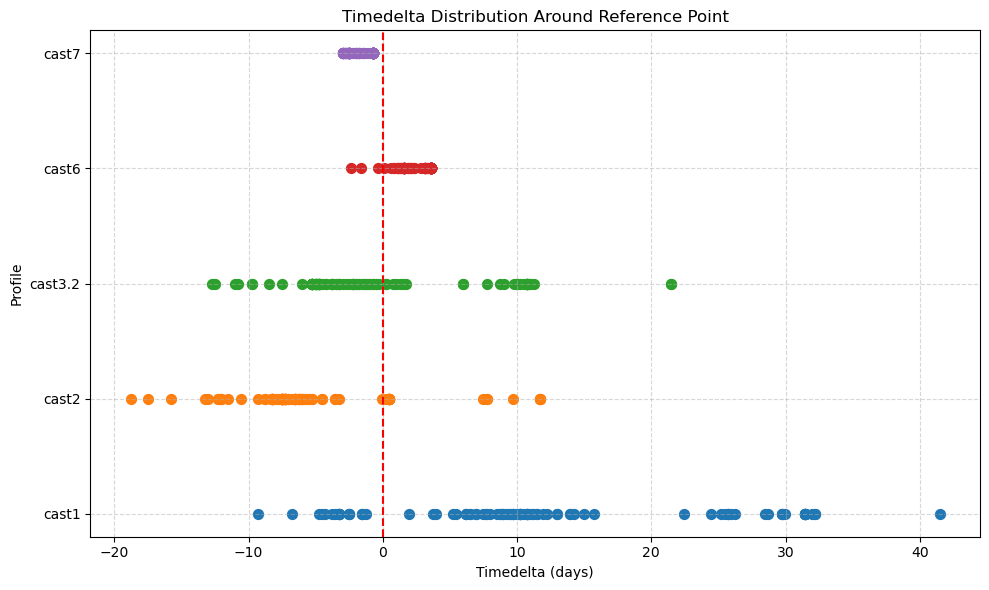

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns

data = parcel_time

# # Convert to DataFrame for plotting
# records = []
# for profile, td_list in data.items():
#     for td in td_list:
#         records.append({'profile': profile, 'days': td.total_seconds() / (24 * 3600)})

# df = pd.DataFrame(records)

# # Plot
# plt.figure(figsize=(10, 6))
# sns.stripplot(data=df, x='days', y='profile', jitter=True, size=6)

# plt.axvline(0, color='red', linestyle='--', label='Reference point')  # Optional reference line
# plt.xlabel('Timedelta (days)')
# plt.ylabel('Profile')
# plt.title('Timedelta Distribution Around Reference Point')
# plt.legend()
# plt.tight_layout()
# plt.show()

# Prepare data for plotting
profiles = list(data.keys())
y_positions = range(len(profiles))

plt.figure(figsize=(10, 6))

for y, profile in zip(y_positions, profiles):
    tds = data[profile]
    # Convert to days
    days = [td.total_seconds() / (24 * 3600) for td in tds]
    plt.scatter(days, [y]*len(days), label=profile, s=50)

# Formatting
plt.yticks(y_positions, profiles)
plt.axvline(0, color='red', linestyle='--', label='Reference Point')
plt.xlabel('Timedelta (days)')
plt.ylabel('Profile')
plt.title('Timedelta Distribution Around Reference Point')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

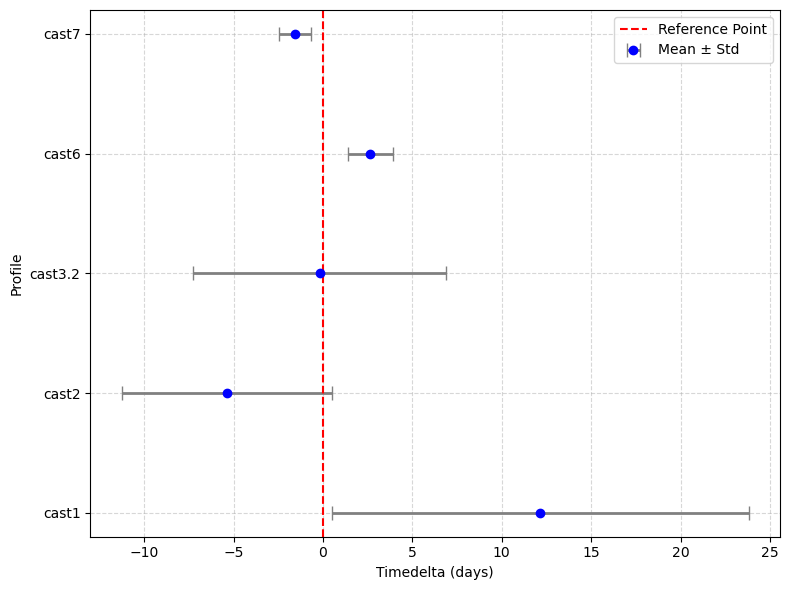

In [11]:
# Prepare data
profiles = list(data.keys())
means = []
stds = []

for profile in profiles:
    tds = data[profile]
    days = np.array([td.total_seconds() / (24 * 3600) for td in tds])
    means.append(np.mean(days))
    stds.append(np.std(days))

# Plot
plt.figure(figsize=(8, 6))
y_positions = np.arange(len(profiles))

plt.errorbar(
    means, y_positions,
    xerr=stds,
    fmt='o',
    color='blue',
    ecolor='gray',
    elinewidth=2,
    capsize=5,
    label='Mean ± Std'
)

# Formatting
plt.axvline(0, color='red', linestyle='--', label='Reference Point')
plt.yticks(y_positions, profiles)
plt.xlabel('Timedelta (days)')
plt.ylabel('Profile')
# plt.title('Mean Timedelta with Error Bars')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()